# LOGISTIC REGRESSION - C KUAT (C=0.01)

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression (L2)
* **Varian**: Penalti Sangat Kuat (C = 0.01)
* **Konsep**: Parameter C adalah kebalikan dari kekuatan regularisasi. Nilai C yang sangat kecil (0.01) berarti penalti sangat ketat. Model dipaksa untuk memiliki bobot yang sangat kecil, membuat model menjadi sangat sederhana dan mencegah overfitting ekstrem, namun berisiko mengalami underfitting.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression L2 dengan C Sangat Kuat (0.01)
model = LogisticRegression(penalty='l2', solver='lbfgs', C=0.01, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - C KUAT (0.01)")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : L2 Regularization (C=0.01)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - C KUAT (0.01)
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : L2 Regularization (C=0.01)
3. Akurasi          : 0.8933
4. Precision (Macro): 0.9005
5. Recall (Macro)   : 0.8933
6. F1-Score (Macro) : 0.8929
7. F1-Score (Weighted): 0.8929
8. Waktu Eksekusi   : 0.0149 detik
9. Penggunaan Memori: 0.59 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.85      0.96      0.90       150
   Hoaks (1)       0.95      0.83      0.89       150

    accuracy                           0.89       300
   macro avg       0.90      0.89      0.89       300
weighted avg       0.90      0.89      0.89       300



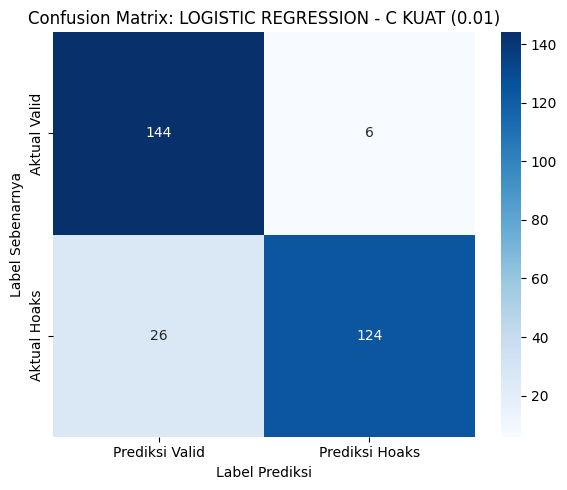

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - C KUAT (0.01)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (L2 dengan C Kuat = 0.01)

1. **Analisis Performa & Akurasi**:
   * Model dengan penalti sangat ketat (C=0.01) menghasilkan akurasi sebesar **89.33%**, sedikit menurun dibandingkan model L2 standar (C=1.0) yang mencapai 91.00%.
   * Dari Confusion Matrix, model ini sangat baik dalam mengenali berita Valid (144 benar, hanya 6 salah). Namun, model mulai kesulitan mengenali berita Hoaks (26 Hoaks lolos ditebak sebagai Valid). Hal ini menyebabkan nilai Recall untuk kelas Hoaks menurun menjadi 0.83 (dari sebelumnya 0.90).

2. **Efek Penalti Sangat Kuat (Underfitting)**:
   * Parameter `C` berbanding terbalik dengan kekuatan penalti. Nilai `C=0.01` memaksa model untuk memiliki bobot yang sangat kecil (mendekati nol). 
   * Akibatnya, model menjadi terlalu sederhana dan kurang "berani" dalam memberikan bobot tinggi pada kata-kata kunci hoaks (seperti "viralkan", "awas", dll). Fenomena ini disebut sebagai **Underfitting**: model terlalu dikekang sehingga kehilangan kemampuan untuk menangkap pola yang lebih kompleks dari data teks.

3. **Efisiensi Komputasi**:
   * Meski akurasinya sedikit turun, model ini tetap sangat efisien (0.0149 detik dan 0.59 MB). Hal ini membuktikan bahwa penalti yang kuat membuat proses optimasi menjadi lebih cepat karena ruang pencarian bobot menjadi jauh lebih kecil.